In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
import sys

print(sys.executable)
print(sys.version)

d:\data-science-llm-inference\.venv\Scripts\python.exe
3.10.6 (tags/v3.10.6:9c7b4bd, Aug  1 2022, 21:53:49) [MSC v.1932 64 bit (AMD64)]


In [4]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.2.0


In [5]:
df = pd.read_csv("../data/processed/feature_engineered_data.csv")

print("Dataset shape:", df.shape)

Dataset shape: (50000, 34)


In [6]:
print("Columns:", len(df.columns))
print("\nFirst 5 rows:")
display(df.head())

Columns: 34

First 5 rows:


,Customer_ID,Age,Gender,Annual_Income,Occupation,Card_Type,Credit_Limit,Card_Age_Months,Monthly_Spending,Monthly_Transactions,...,EMI_Count,International_Transactions,Reward_Points_Earned,Reward_Points_Redeemed,Mobile_App_Login,Credit_Score,calculated_monthly_spending,spending_difference,calculated_utilization,spending_relative_difference
0,CC100000,33,M,787406,Self-Employed,Silver,220000.0,20,36733.49,83,...,2,0,1081,210,23,492,65617.166667,-28883.676667,0.166970,-0.440185
1,CC100001,58,M,598084,Retired,Basic,112000.0,101,30212.78,72,...,2,0,606,163,22,607,49840.333333,-19627.553333,0.269757,-0.393809
2,CC100002,40,F,1710737,Private Employee,Platinum,928000.0,12,115895.71,142,...,2,3,6857,0,48,549,142561.416667,-26665.706667,0.124888,-0.187047
3,CC100003,42,M,712664,Private Employee,Silver,211000.0,54,21804.26,64,...,3,1,660,369,13,740,59388.666667,-37584.406667,0.103338,-0.632855
4,CC100004,19,M,1504662,Government Employee,Gold,572000.0,44,91039.33,67,...,5,0,3673,1322,37,570,125388.500000,-34349.170000,0.159160,-0.273942


In [7]:
target_column = "Credit_Score"

print("Target column:", target_column)
print("Target data type:", df[target_column].dtype)

print("\nTarget statistics:")
print(df[target_column].describe())

Target column: Credit_Score
Target data type: int64

Target statistics:
count    50000.000000
mean       628.984580
std         68.444249
min        367.000000
25%        585.000000
50%        638.000000
75%        681.000000
max        792.000000
Name: Credit_Score, dtype: float64


In [8]:
target_column = "Credit_Score"
id_column = "Customer_ID"

feature_columns = [
    col for col in df.columns
    if col not in [target_column, id_column]
]

X = df[feature_columns].copy()
y = df[target_column].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nCategorical columns:")
print(X.select_dtypes(include=["object"]).columns.tolist())

X shape: (50000, 32)
y shape: (50000,)

Categorical columns:
['Gender', 'Occupation', 'Card_Type']


In [9]:
# One-hot encode categorical features

X_encoded = pd.get_dummies(
    X,
    columns=["Gender", "Occupation", "Card_Type"],
    drop_first=True
)

print("Original feature count:", X.shape[1])
print("Encoded feature count:", X_encoded.shape[1])

print("\nEncoded data shape:", X_encoded.shape)

Original feature count: 32
Encoded feature count: 39

Encoded data shape: (50000, 39)


In [10]:
print("Data types:")
print(X_encoded.dtypes.value_counts())

print("\nMissing values:")
print(X_encoded.isnull().sum().sum())

print("\nFirst 5 rows:")
display(X_encoded.head())

Data types:
float64    20
bool       10
int64       9
Name: count, dtype: int64

Missing values:
0

First 5 rows:


,Age,Annual_Income,Credit_Limit,Card_Age_Months,Monthly_Spending,Monthly_Transactions,Avg_Transaction_Value,Online_Shopping_Spending,Grocery_Spending,Fuel_Spending,...,Gender_M,Occupation_Government Employee,Occupation_Private Employee,Occupation_Retired,Occupation_Self-Employed,Occupation_Student,Card_Type_Gold,Card_Type_Platinum,Card_Type_Signature,Card_Type_Silver
0,33,787406,220000.0,20,36733.49,83,427.21,1317.13,9400.14,4339.48,...,True,False,False,False,True,False,False,False,False,True
1,58,598084,112000.0,101,30212.78,72,399.89,3892.84,6134.61,3442.74,...,True,False,False,True,False,False,False,False,False,False
2,40,1710737,928000.0,12,115895.71,142,837.85,13547.09,40293.00,11946.73,...,False,False,True,False,False,False,False,True,False,False
3,42,712664,211000.0,54,21804.26,64,357.05,7582.70,5597.02,1207.37,...,True,False,True,False,False,False,False,False,False,True
4,19,1504662,572000.0,44,91039.33,67,1367.05,19793.91,9898.38,13911.88,...,True,True,False,False,False,False,True,False,False,False


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (40000, 39)
Testing features: (10000, 39)
Training target: (40000,)
Testing target: (10000,)


In [12]:
print("Training target statistics:")
print(y_train.describe())

print("\nTesting target statistics:")
print(y_test.describe())

Training target statistics:
count    40000.000000
mean       628.973025
std         68.362464
min        367.000000
25%        585.000000
50%        638.000000
75%        681.000000
max        777.000000
Name: Credit_Score, dtype: float64

Testing target statistics:
count    10000.000000
mean       629.030800
std         68.773827
min        378.000000
25%        585.000000
50%        638.000000
75%        681.000000
max        792.000000
Name: Credit_Score, dtype: float64


In [13]:
# Convert boolean columns to integers

X_train = X_train.astype(float)
X_test = X_test.astype(float)

print("X_train dtypes:")
print(X_train.dtypes.value_counts())

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train dtypes:
float64    39
Name: count, dtype: int64

X_train shape: (40000, 39)
X_test shape: (10000, 39)


In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (40000, 39)
Scaled testing shape: (10000, 39)


In [15]:
# Train Linear Regression model

linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [16]:
# Predictions using Linear Regression

y_pred_linear = linear_model.predict(X_test_scaled)

print("First 10 predictions:")
print(y_pred_linear[:10])

First 10 predictions:
[591.96136107 727.72197479 654.34269787 725.60858059 564.29946644
 653.61933027 408.57414097 631.05549712 581.03378689 662.2452644 ]


In [17]:
# Evaluate Linear Regression

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("--------------------------------")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression Performance
--------------------------------
MAE : 10.170601224253419
RMSE: 12.748098864599013
R²  : 0.9656372511613248


In [18]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [19]:
y_pred_rf = random_forest_model.predict(X_test)

print("First 10 Random Forest predictions:")
print(y_pred_rf[:10])

First 10 Random Forest predictions:
[585.64 729.43 645.86 721.08 574.01 653.03 421.94 638.02 574.69 661.45]


In [20]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Performance
--------------------------------
MAE : 10.901673
RMSE: 13.671917960915358
R²  : 0.9604764505865352


In [21]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [22]:
y_pred_xgb = xgb_model.predict(X_test)

print("First 10 XGBoost predictions:")
print(y_pred_xgb[:10])

First 10 XGBoost predictions:
[589.35376 730.1284  655.2674  726.7584  570.23254 655.05756 416.16202
 629.62305 581.49554 662.4197 ]


In [23]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Performance")
print("--------------------------------")
print("MAE :", mae_xgb)
print("RMSE:", rmse_xgb)
print("R²  :", r2_xgb)

XGBoost Performance
--------------------------------
MAE : 9.9335355758667
RMSE: 12.455220695877204
R²  : 0.9671980142593384


In [24]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        mae_linear,
        mae_rf,
        mae_xgb
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf,
        rmse_xgb
    ],
    "R2": [
        r2_linear,
        r2_rf,
        r2_xgb
    ]
})

model_results = model_results.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

display(model_results)

,Model,MAE,RMSE,R2
0,XGBoost,9.933536,12.455221,0.967198
1,Linear Regression,10.170601,12.748099,0.965637
2,Random Forest,10.901673,13.671918,0.960476


In [25]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(15))

,Feature,Importance
0,Payment_Ratio,0.627709
1,Credit_Utilization,0.318421
2,International_Transactions,0.006685
3,Cash_Advance_Amount,0.006623
4,EMI_Count,0.004997
5,Card_Age_Months,0.004912
6,Mobile_App_Login,0.004112
7,Reward_Points_Earned,0.002534
8,Payment_Amount,0.001812
9,Card_Type_Platinum,0.001687


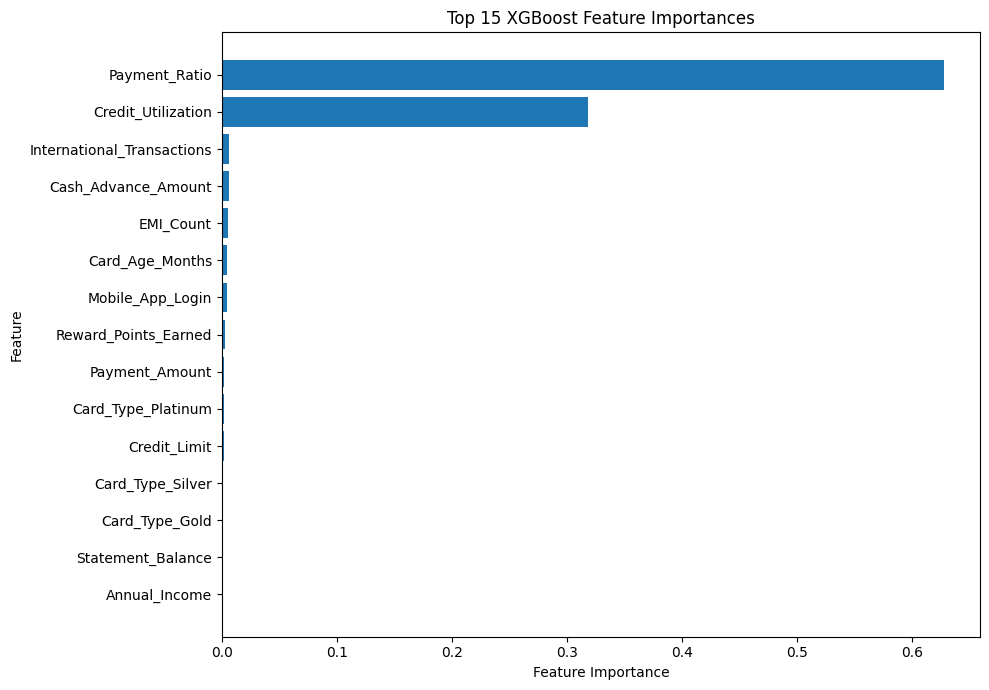

In [26]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

In [27]:
model_results.to_csv(
    "../results/model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "../results/xgboost_feature_importance.csv",
    index=False
)

print("Model comparison saved.")
print("Feature importance saved.")

Model comparison saved.
Feature importance saved.


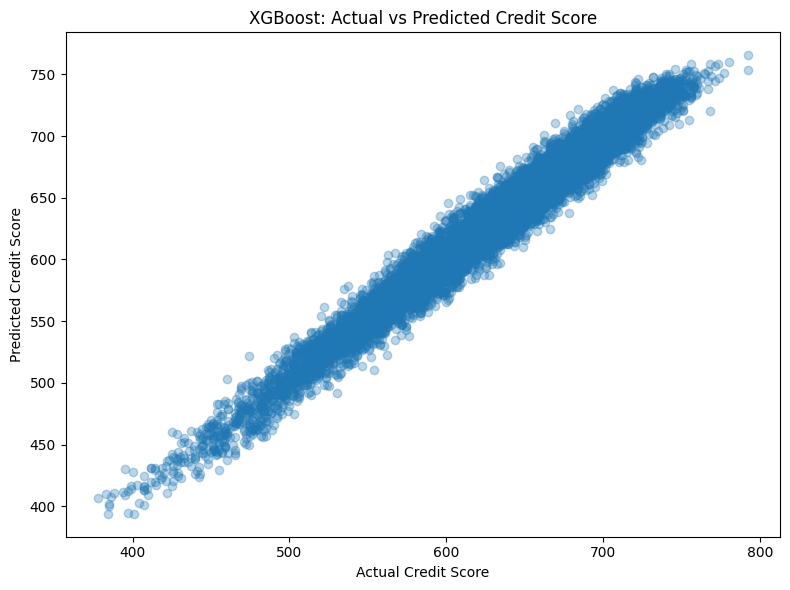

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_xgb,
    alpha=0.3
)

plt.xlabel("Actual Credit Score")
plt.ylabel("Predicted Credit Score")
plt.title("XGBoost: Actual vs Predicted Credit Score")

plt.tight_layout()
plt.show()

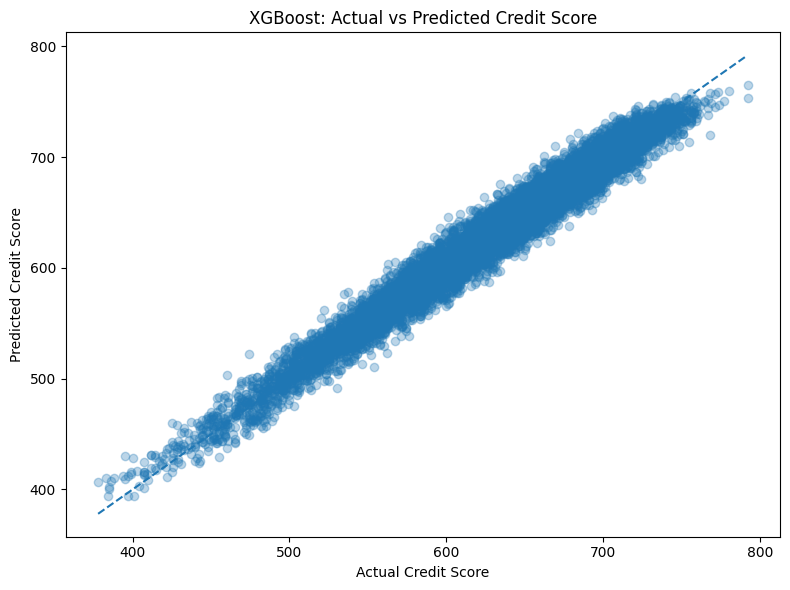

In [29]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_xgb,
    alpha=0.3
)

min_score = min(y_test.min(), y_pred_xgb.min())
max_score = max(y_test.max(), y_pred_xgb.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--"
)

plt.xlabel("Actual Credit Score")
plt.ylabel("Predicted Credit Score")
plt.title("XGBoost: Actual vs Predicted Credit Score")

plt.tight_layout()
plt.show()

In [30]:
residuals = y_test - y_pred_xgb

print("Residual Statistics")
print("--------------------------------")
print("Mean Residual:", residuals.mean())
print("Minimum Residual:", residuals.min())
print("Maximum Residual:", residuals.max())
print("Mean Absolute Residual:", np.abs(residuals).mean())

Residual Statistics
--------------------------------
Mean Residual: 0.05660192565917969
Minimum Residual: -47.91119384765625
Maximum Residual: 48.1082763671875
Mean Absolute Residual: 9.933536032104492


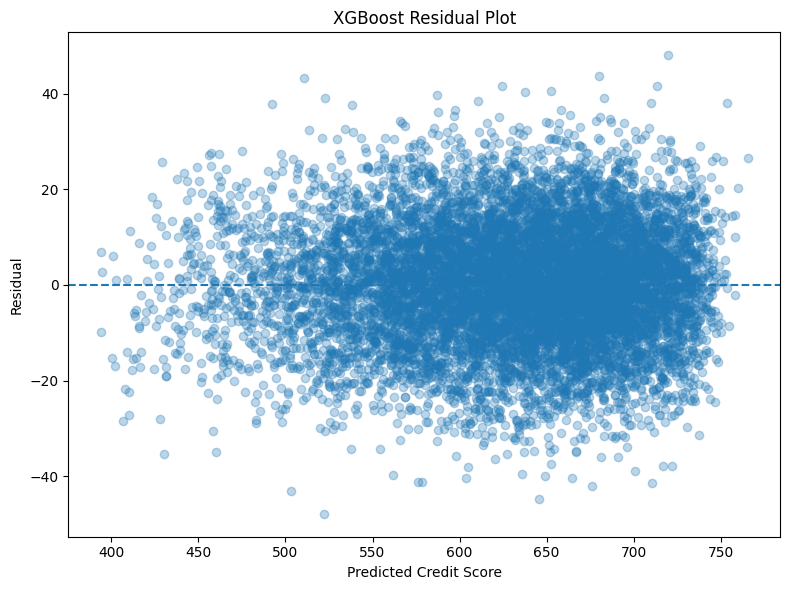

In [31]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_xgb,
    residuals,
    alpha=0.3
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Credit Score")
plt.ylabel("Residual")
plt.title("XGBoost Residual Plot")

plt.tight_layout()
plt.show()

In [35]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("SHAP version:", shap.__version__)

XGBoost version: 3.2.0
SHAP version: 0.49.1


In [36]:
# Check how XGBoost 3.2.0 stores the base score

booster = xgb_model.get_booster()

config = booster.save_config()

print(config[:3000])

{"learner":{"generic_param":{"device":"cpu","fail_on_invalid_gpu_id":"0","n_jobs":"-1","nthread":"-1","random_state":"42","seed":"42","seed_per_iteration":"0","validate_parameters":"1"},"gradient_booster":{"gbtree_model_param":{"num_parallel_tree":"1","num_trees":"100"},"gbtree_train_param":{"process_type":"default","tree_method":"auto","updater":"grow_quantile_histmaker","updater_seq":"grow_quantile_histmaker"},"name":"gbtree","specified_updater":false,"tree_train_param":{"alpha":"0","colsample_bylevel":"1","colsample_bynode":"1","colsample_bytree":"1","eta":"0.100000001","gamma":"0","grow_policy":"depthwise","interaction_constraints":"","lambda":"1","learning_rate":"0.100000001","max_bin":"256","max_cat_threshold":"64","max_cat_to_onehot":"4","max_delta_step":"0","max_depth":"6","max_leaves":"0","min_child_weight":"1","min_split_loss":"0","monotone_constraints":"()","refresh_leaf":"1","reg_alpha":"0","reg_lambda":"1","sampling_method":"uniform","sparse_threshold":"0.20000000000000001

In [37]:
import copy
import json
import xgboost as xgb

# Make a copy so the original trained model remains untouched
xgb_shap_model = copy.deepcopy(xgb_model)

# Get the model configuration
config = json.loads(xgb_shap_model.get_booster().save_config())

# Fix XGBoost 3.2.0 vector-style base_score for SHAP
base_score = config["learner"]["learner_model_param"]["base_score"]

if isinstance(base_score, str) and base_score.startswith("["):
    base_score = base_score.strip("[]")
    
config["learner"]["learner_model_param"]["base_score"] = base_score

# Apply the corrected configuration
xgb_shap_model.get_booster().load_config(json.dumps(config))

print("Temporary SHAP-compatible model created.")
print("Corrected base_score:", base_score)

Temporary SHAP-compatible model created.
Corrected base_score: 6.28973E2


In [39]:
# Save trained XGBoost model and test data for explainability

import os

os.makedirs("../models/ml", exist_ok=True)

# Save XGBoost model
xgb_model.save_model("../models/ml/xgb_model.json")

# Save the exact test features used by XGBoost
X_test.to_csv("../models/ml/xgb_X_test.csv", index=False)

# Save the corresponding target values
y_test.to_csv("../models/ml/xgb_y_test.csv", index=False)

print("XGBoost model saved successfully.")
print("X_test saved successfully.")
print("y_test saved successfully.")

print("\nX_test shape:", X_test.shape)
print("Number of model features:", len(xgb_model.feature_names_in_))


XGBoost model saved successfully.
X_test saved successfully.
y_test saved successfully.

X_test shape: (10000, 39)
Number of model features: 39
